# EECE5644 Recitation: Naive Bayes Classifiers
### Heart-disease diagnosis with continuous, categorical, binary, and mixed features

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import logsumexp
from scipy.stats import norm
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, CategoricalNB, BernoulliNB
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix
from IPython.display import display

# Fixed seeds make the classroom demonstration reproducible.
SEED = 42
COLORS = ['#2676b8', '#d65e32']
CLASS_NAMES = ['No disease (0)', 'Disease (1)']
plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 11, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titlesize': 12, 'figure.facecolor': 'white'
})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', None)

## 1. The problem: heart-disease diagnosis

A patient is referred to a cardiology clinic. From routine measurements, an exercise
test, and two imaging tests, **should the patient be flagged for heart disease?**

**Dataset:** *Statlog (Heart)* from the UCI repository, loaded from OpenML
(`data_id=53`, cached after the first run). One row = one patient; 270 patients, no
missing values. **Label** `class`: heart disease `absent` (150, `y = 0`) or `present`
(120, 44%, `y = 1`). **Features:** 13 measurements of three types:

| `X_mixed` column | Block, index $j$ | Column in the data | Meaning | Values |
|---:|---|---|---|---|
| 0 | continuous, $j=0$ | `age` | Age | 29–77 years |
| 1 | continuous, $j=1$ | `resting_blood_pressure` | Blood pressure at rest | 94–200 mm Hg |
| 2 | continuous, $j=2$ | `serum_cholestoral` | Cholesterol in the blood | 126–564 mg/dl |
| 3 | continuous, $j=3$ | `maximum_heart_rate_achieved` | Highest heart rate in the exercise test | 71–202 bpm |
| 4 | continuous, $j=4$ | `oldpeak` | ST depression during exercise, relative to rest | 0–6.2 mm; exactly 0 for 31% |
| 5 | categorical, $j=0$ | `chest` | Chest-pain type | 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic |
| 6 | categorical, $j=1$ | `resting_electrocardiographic_results` | Resting ECG | 0 normal, 1 ST-T abnormality, 2 LV hypertrophy (thickened heart wall) |
| 7 | categorical, $j=2$ | `slope` | Shape of the ST segment at peak exercise | 1 upsloping, 2 flat, 3 downsloping |
| 8 | categorical, $j=3$ | `number_of_major_vessels` | Major vessels colored by fluoroscopy | 0, 1, 2, 3 |
| 9 | categorical, $j=4$ | `thal` | Thallium stress test | 3 normal, 6 fixed defect, 7 reversible defect |
| 10 | binary, $j=0$ | `sex` | Sex | 1 male, 0 female |
| 11 | binary, $j=1$ | `fasting_blood_sugar` | Fasting blood sugar > 120 mg/dl | 1 yes, 0 no |
| 12 | binary, $j=2$ | `exercise_induced_angina` | Chest pain during the exercise test | 1 yes, 0 no |

**In code:** `X_mixed` (270 × 13) has the columns in the order above, and `X_cont`,
`X_cat`, `X_bin` are its three blocks. **Inside a block, $j$ restarts at 0**; every
parameter below is indexed by the class $c$ and this $j$. The categorical codes are
labels, not quantities, and `CategoricalNB` needs them numbered $k=0,\ldots,K_j-1$, so
`encode` replaces each code by its position in the Values column (e.g. thal 3, 6, 7 →
$k$ = 0, 1, 2).

We also follow one **new patient** (not one of the 270) through Parts 4 to 6.

In [2]:
heart = fetch_openml(data_id=53, as_frame=True).frame  # Statlog (Heart), 270 patients.

continuous = ['age', 'resting_blood_pressure', 'serum_cholestoral',
              'maximum_heart_rate_achieved', 'oldpeak']
# Known codes and meanings of each categorical feature (from the dataset documentation).
categorical = {
    'chest': {1: 'typical angina', 2: 'atypical angina', 3: 'non-anginal pain', 4: 'asymptomatic'},
    'resting_electrocardiographic_results': {0: 'normal', 1: 'ST-T abnormality', 2: 'LV hypertrophy'},
    'slope': {1: 'upsloping', 2: 'flat', 3: 'downsloping'},  # ST segment during exercise
    'number_of_major_vessels': {0: '0', 1: '1', 2: '2', 3: '3'},
    'thal': {3: 'normal', 6: 'fixed defect', 7: 'reversible defect'}
}
binary = ['sex', 'fasting_blood_sugar', 'exercise_induced_angina']  # sex: 1 = male

def encode(frame):
    """Raw patient table -> numeric matrix with columns [continuous | categorical | binary].
    Each category code is replaced by its position k = 0, ..., K-1."""
    positions = np.column_stack([
        frame[col].map({code: k for k, code in enumerate(meanings)}) for col, meanings in categorical.items()
    ])
    assert not np.isnan(positions).any(), 'A category code is missing from the known codes.'
    return np.column_stack([frame[continuous].to_numpy(float), positions, frame[binary].to_numpy(float)])

X_mixed = encode(heart)
y = (heart['class'] == 'present').to_numpy().astype(int)
cols_cont, cols_cat, cols_bin = list(range(0, 5)), list(range(5, 10)), list(range(10, 13))
X_cont = X_mixed[:, cols_cont]
X_cat = X_mixed[:, cols_cat].astype(int)
X_bin = X_mixed[:, cols_bin].astype(int)
category_sizes = [len(meanings) for meanings in categorical.values()]  # K_j: known schema, not inferred.

# Short feature names in X_mixed column order; every table below uses them.
feature_names = ['age', 'resting BP', 'cholesterol', 'max heart rate', 'ST depression',
                 'chest pain', 'resting ECG', 'ST slope', 'major vessels', 'thal',
                 'male', 'fasting blood sugar > 120', 'exercise angina']
units = ['years', 'mm Hg', 'mg/dl', 'bpm', 'mm']  # Units of the five continuous features.

def readable(raw):
    """One raw patient row -> 'feature = value' strings, in X_mixed column order."""
    return ([f'{name} = {float(raw[col]):g} {unit}'
             for name, col, unit in zip(feature_names[:5], continuous, units)]
            + [f'{name} = {categorical[col][int(raw[col])]}'
               for name, col in zip(feature_names[5:10], categorical)]
            + [f'{name} = {"yes" if raw[col] == 1 else "no"}'
               for name, col in zip(feature_names[10:], binary)])

display(heart.head())
print(f'{len(y)} patients, {y.sum()} with heart disease ({y.mean():.0%})')

# The new patient, written with the same raw codes as the data.
new_patient_raw = pd.DataFrame([{
    'age': 62, 'sex': 1, 'chest': 3, 'resting_blood_pressure': 150, 'serum_cholestoral': 280,
    'fasting_blood_sugar': 0, 'resting_electrocardiographic_results': 2,
    'maximum_heart_rate_achieved': 130, 'exercise_induced_angina': 1, 'oldpeak': 0.4,
    'slope': 1, 'number_of_major_vessels': 1, 'thal': 3
}])
new_patient = encode(new_patient_raw)  # Shape (1, 13), same columns as X_mixed.
new_text = readable(new_patient_raw.iloc[0])
print('\nNew patient')
for block, columns in [('continuous', cols_cont), ('categorical', cols_cat), ('binary', cols_bin)]:
    print(f'  {block:11s}: ' + '; '.join(new_text[col] for col in columns))

,age,sex,chest,resting_blood_pressure,serum_cholestoral,fasting_blood_sugar,resting_electrocardiographic_results,maximum_heart_rate_achieved,exercise_induced_angina,oldpeak,slope,number_of_major_vessels,thal,class
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,present
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,absent
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,present
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,absent
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,absent


270 patients, 120 with heart disease (44%)

New patient
  continuous : age = 62 years; resting BP = 150 mm Hg; cholesterol = 280 mg/dl; max heart rate = 130 bpm; ST depression = 0.4 mm
  categorical: chest pain = non-anginal pain; resting ECG = LV hypertrophy; ST slope = upsloping; major vessels = 1; thal = normal
  binary     : male = yes; fasting blood sugar > 120 = no; exercise angina = yes


## 2. What is Naive Bayes?
**What it is for.** Naive Bayes is a **probabilistic classifier**: given the features $x$
of one example, it returns the probability of every class, $P(y=c\mid x)$, and predicts
the most probable class. Here: from a patient's 13 measurements, $P(\text{disease}\mid x)$.
Typical uses:
- **Text classification**, its classic application: spam filtering, sorting documents by
  topic, sentiment. Every word is a feature, so there are thousands of features.
- **Diagnosis and screening** from a mix of measurements, as in this recitation.
- A **fast first model (baseline)**: training only counts and averages, it works with
  small data sets and many features, it handles mixed feature types, and the
  contribution of each feature to a decision can be read off directly (Part 9).

**How it works.** Instead of learning $P(y\mid x)$ directly, Naive Bayes learns from the
training data how common each class is and what the features look like within each
class. Bayes' rule then turns these around:

$$\underbrace{P(y=c\mid x)}_{\text{posterior}}\;\propto\;
\underbrace{P(y=c)}_{\text{prior}}\;\underbrace{p(x\mid y=c)}_{\text{likelihood}}.$$

**Why "naive".** $p(x\mid y=c)$ is a distribution over all 13 features *together*. The
discrete features alone can be combined in $4\cdot3\cdot3\cdot4\cdot3\cdot2^3=3456$ ways per
class, far more than our 162 training patients. Naive Bayes therefore makes
**one key assumption**:

> **The naive assumption: within each class, the features are independent.** Once the
> diagnosis is known, knowing one feature tells us nothing more about another.

$$p(x\mid y=c)=\prod_{j}p(x_j\mid y=c)$$

So each feature needs only its own one-dimensional distribution: a mean and a variance,
a small table, or a single probability.

**Independent *given the class*, not independent overall.** The table below checks the
assumption on the 162 training patients (Part 3). Each number is the (Pearson)
**correlation coefficient** $r$ of two features $a$ and $b$ over a group of $m$ patients:

$$r=\frac{\sum_{i=1}^{m}(a_i-\bar a)(b_i-\bar b)}
{\sqrt{\sum_{i=1}^{m}(a_i-\bar a)^2\;\sum_{i=1}^{m}(b_i-\bar b)^2}},$$

where $a_i$ and $b_i$ are the two features of patient $i$, and $\bar a$ and $\bar b$ are
their averages over the group. The numerator is positive when the two features tend to
be above (or below) their averages at the same time, and negative when one tends to be
above while the other is below. The denominator removes the units, so $-1\le r\le1$.
In code: `np.corrcoef(a, b)[0, 1]`.

- **Reading $r$:** $r>0$: when one feature is high, the other tends to be high too.
  $r<0$: when one is high, the other tends to be low. $r\approx0$: no linear relation.
  Roughly, $|r|<0.2$ is weak and $|r|\approx0.4$–$0.5$ is moderate.
- **The three columns use different groups of patients:** **all 162** uses every
  training patient ($m=162$); **90 without disease** uses only the patients with $y=0$
  ($m=90$); **72 with disease** uses only those with $y=1$ ($m=72$).
- **Categorical feature:** ST slope has three categories, so for the second row it is
  first turned into a 0/1 feature (1 = flat or downsloping, 0 = upsloping); the same
  formula then applies.
- **What to look for:** the naive assumption says that the two **within-class** columns
  should be close to 0. The **all 162** column may be far from 0, and that is allowed.

Why can the **All** column be far from 0 when the classes are not? Patients with disease
tend to have *both* a lower maximum heart rate *and* a larger ST depression. Mixing the
two classes therefore creates a correlation even if, within each class, the two features
were unrelated: the diagnosis is their common cause.

| Pair of features | $r$, all 162 | $r$, 90 without disease | $r$, 72 with disease | What it means |
|---|---:|---:|---:|---|
| max heart rate and ST depression | −0.32 | −0.11 | −0.20 | Overall, a higher heart rate goes with a smaller ST depression. Within each class the relation is weak, so most of it comes from the diagnosis: the assumption **roughly holds**. |
| ST depression and "ST slope is flat or downsloping" (1 = yes, 0 = upsloping) | 0.53 | 0.41 | 0.41 | A larger ST depression goes with a flat or downsloping ST segment, and the relation stays moderate within both classes, because both describe the same ST segment: the assumption is **violated**. |
| age and max heart rate | −0.46 | −0.54 | −0.23 | Older patients reach lower heart rates, also within each class (−0.54 among the patients without disease): the assumption is **violated**. |

The assumption is rarely true, hence "naive". Correlated features count shared evidence
more than once, which pushes the probabilities toward 0 or 1. Naive Bayes often
classifies well anyway, but its probabilities tend to be overconfident (Part 8).

**Computing it.** With logarithms,

$$s_c(x)=\log\pi_c+\sum_{j}\log p(x_j\mid y=c),\qquad \hat y=\arg\max_c s_c(x),$$

and the posteriors are the normalized scores,
$P(y=c\mid x)=\exp\left(s_c(x)-\operatorname{logsumexp}_{c'}s_{c'}(x)\right)$.

| Symbol | Here | In code |
|---|---|---|
| $y$, $c$ | Diagnosis / one class: 0 = no disease, 1 = disease | `y`; the row index of every parameter array |
| $x$, $x_j$ | The 13 features of one patient / one of them | one row of `X_mixed` / one column of a block |
| $\pi_c$ | Prior $P(y=c)$, before any feature is seen | `class_prior_` |

Only $p(x_j\mid y=c)$ changes with the feature type:

| Feature type | Likelihood | scikit-learn estimator |
|---|---|---|
| Continuous, e.g. maximum heart rate | One Gaussian density per feature and class | `GaussianNB` |
| Categorical, e.g. chest-pain type | One probability table per feature and class | `CategoricalNB` |
| Binary, e.g. exercise-induced angina | One Bernoulli probability per feature and class | `BernoulliNB` |
| A mixture of the above | Add the log likelihoods of all feature blocks | Part 6 |

In [3]:
def probabilities_from_scores(scores):
    """Normalize log class scores (rows = samples, columns = classes) into posteriors."""
    return np.exp(scores - logsumexp(scores, axis=1, keepdims=True))

## 3. Cut the data into train, validation, and test
The patients are split **once**, and every model below reuses the same rows:

| Subset | Patients | Job |
|---|---:|---|
| Train (60%) | 162 | Fit the parameters: means, variances, probability tables, priors |
| Validation (20%) | 54 | Choose α, the prior, and the model |
| Test (20%) | 54 | Report performance after all choices are fixed |

`stratify=y` keeps the disease fraction (44%) equal in each subset. The training rows
contain $N_0=90$ patients without and $N_1=72$ with heart disease.

In [4]:
n = len(y)
# First hold out 20% for test; then reserve 25% of the remaining 80% for validation.
train_val_idx, test_idx = train_test_split(
    np.arange(n), test_size=0.20, stratify=y, random_state=SEED
)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.25, stratify=y[train_val_idx], random_state=SEED + 1
)
display(pd.DataFrame([
    {'subset': name, 'patients': len(idx), 'no disease (c=0)': np.sum(y[idx] == 0),
     'disease (c=1)': np.sum(y[idx] == 1)}
    for name, idx in {'train': train_idx, 'validation': val_idx, 'test': test_idx}.items()
]))
assert len(set(train_idx) | set(val_idx) | set(test_idx)) == n  # Disjoint and complete.

,subset,patients,no disease (c=0),disease (c=1)
0,train,162,90,72
1,validation,54,30,24
2,test,54,30,24


## 4. Continuous features: Gaussian NB
For class $c$ and continuous feature $j$,

$$p(x_j\mid y=c)=\frac{1}{\sqrt{2\pi\sigma_{cj}^{2}}}
\exp\left[-\frac{(x_j-\mu_{cj})^2}{2\sigma_{cj}^{2}}\right].$$

| Symbol | Attribute | Shape | Meaning here |
|---|---|---|---|
| $\mu_{cj}$ | `theta_[c, j]` | (2, 5) | Average of feature $j$ over the training patients of class $c$ |
| $\sigma^2_{cj}$ | `var_[c, j]` | (2, 5) | Variance of feature $j$ over the same patients |

Rows $c$: 0 no disease, 1 disease. Columns $j$: 0 age, 1 resting BP, 2 cholesterol,
3 maximum heart rate, 4 ST depression. For example, `theta_[1, 3]` is the average
maximum heart rate of the training patients with disease.

Per class, the five 1-D Gaussians together form **one 5-D Gaussian with diagonal
covariance**: mean $(\mu_{c0},\ldots,\mu_{c4})$ and covariance
$\operatorname{diag}(\sigma^2_{c0},\ldots,\sigma^2_{c4})$. All covariances between
features are 0, which is the naive assumption for continuous features. A full 5-D
Gaussian, as in QDA, would also estimate 10 covariances per class.

```python
model = GaussianNB(priors=None)   # None: learn class proportions from the training data
model.fit(X_train, y_train)
probabilities = model.predict_proba(X_new)
```

For the new patient, the code also computes how much each feature pushes toward disease (its **contribution**); the columns of that table are explained below it.

In [5]:
gnb_demo = GaussianNB().fit(X_cont[train_idx], y[train_idx])

# theta_ and var_ are just the per-class sample means and variances of each feature.
X_train, y_train = X_cont[train_idx], y[train_idx]
for c in [0, 1]:
    assert np.allclose(gnb_demo.theta_[c], X_train[y_train == c].mean(axis=0))
    assert np.allclose(gnb_demo.var_[c], X_train[y_train == c].var(axis=0))

print('class_prior_ = [pi_0, pi_1] =', gnb_demo.class_prior_.round(3))
display(pd.DataFrame({
    'unit': units,
    'mu_0j': gnb_demo.theta_[0], 'mu_1j': gnb_demo.theta_[1],
    'sigma_0j': np.sqrt(gnb_demo.var_[0]), 'sigma_1j': np.sqrt(gnb_demo.var_[1])
}, index=pd.Index([f'{j}: {name}' for j, name in enumerate(feature_names[:5])], name='feature j')).round(2))

def gaussian_log_likelihood(model, X):
    """Return log p(X | class), excluding the class prior; shape (rows, classes)."""
    X = np.asarray(X)
    difference = X[:, None, :] - model.theta_[None, :, :]
    # Sum over features; do not sum over classes or samples.
    return -0.5 * (
        np.log(2 * np.pi * model.var_)[None, :, :]
        + difference**2 / model.var_[None, :, :]
    ).sum(axis=2)

new_cont = new_patient[:, cols_cont]
# New patient: log density of each feature j in each class c, from theta_[c, j] and var_[c, j].
per_feature = norm.logpdf(new_cont[0], gnb_demo.theta_, np.sqrt(gnb_demo.var_))  # Shape (2, 5).
contribution = per_feature[1] - per_feature[0]  # Positive = favors disease.
display(pd.DataFrame({
    'x_j': new_cont[0], 'log p(x_j | c=0)': per_feature[0], 'log p(x_j | c=1)': per_feature[1],
    'contribution': contribution
}, index=pd.Index([f'{j}: {name}' for j, name in enumerate(feature_names[:5])], name='feature j')).round(3))

# From the five features to the prediction (Part 2): s_c = log pi_c + sum_j log p(x_j | c).
log_likelihood = per_feature.sum(axis=1)                # Naive assumption: add the five log densities.
log_prior = np.log(gnb_demo.class_prior_)
scores = log_likelihood + log_prior                    # s_0, s_1
posterior = probabilities_from_scores(scores[None])[0]  # P(c | x) = exp(s_c) / (exp(s_0) + exp(s_1))
summary = pd.DataFrame({'c=0: no disease': [log_likelihood[0], log_prior[0], scores[0], posterior[0]],
                        'c=1: disease': [log_likelihood[1], log_prior[1], scores[1], posterior[1]]},
                       index=['log likelihood: sum_j log p(x_j | c)', 'log prior: log pi_c',
                              'score s_c', 'posterior P(c | x)'])
summary['c=1 minus c=0'] = summary['c=1: disease'] - summary['c=0: no disease']
summary.loc['posterior P(c | x)', 'c=1 minus c=0'] = np.nan
display(summary.round(3))

y_hat = scores.argmax()
print(f'Prediction: y_hat = argmax_c s_c = {y_hat} ({CLASS_NAMES[y_hat]}), P(disease | x) = {posterior[1]:.4f}')
print('scikit-learn predict_proba:', gnb_demo.predict_proba(new_cont).round(4))
assert np.allclose(log_likelihood, gaussian_log_likelihood(gnb_demo, new_cont)[0])  # Same as the vectorized function.
assert np.allclose(posterior, gnb_demo.predict_proba(new_cont)[0])                  # Same as scikit-learn.

class_prior_ = [pi_0, pi_1] = [0.556 0.444]


,unit,mu_0j,mu_1j,sigma_0j,sigma_1j
feature j,,,,,
0: age,years,52.30,56.56,9.77,7.85
1: resting BP,mm Hg,129.68,136.08,16.43,18.24
2: cholesterol,mg/dl,243.98,253.64,56.91,49.96
3: max heart rate,bpm,159.97,139.93,19.71,20.82
4: ST depression,mm,0.61,1.60,0.83,1.24


,x_j,log p(x_j | c=0),log p(x_j | c=1),contribution
feature j,,,,
0: age,62.0,-3.691,-3.220,0.471
1: resting BP,150.0,-4.483,-4.114,0.369
2: cholesterol,280.0,-5.161,-4.969,0.191
3: max heart rate,130.0,-5.056,-4.068,0.987
4: ST depression,0.4,-0.759,-1.600,-0.841


,c=0: no disease,c=1: disease,c=1 minus c=0
log likelihood: sum_j log p(x_j | c),-19.150,-17.972,1.178
log prior: log pi_c,-0.588,-0.811,-0.223
score s_c,-19.737,-18.783,0.955
posterior P(c | x),0.278,0.722,NaN


Prediction: y_hat = argmax_c s_c = 1 (Disease (1)), P(disease | x) = 0.7221
scikit-learn predict_proba: [[0.2779 0.7221]]


**How the columns of the new-patient table are computed.** One row per feature $j$;
$\mu_{cj}$ and $\sigma_{cj}$ come from the parameter table above it.

- **`log p(x_j | c=0)`, `log p(x_j | c=1)`**: the log of the Gaussian density of class $c$
  at the patient's value $x_j$, i.e. the log of the formula at the top of Part 4:

$$\log p(x_j\mid c)=-\tfrac12\log\left(2\pi\sigma_{cj}^2\right)-\frac{(x_j-\mu_{cj})^2}{2\sigma_{cj}^2}.$$

- **`contribution`**: `log p(x_j | c=1)` minus `log p(x_j | c=0)`. Positive pushes toward
  disease, negative toward no disease. It is large when $x_j$ is much closer to one class
  mean than to the other, relative to the spread $\sigma$.

*Worked row, maximum heart rate = 130 bpm* ($\mu_0=159.97$, $\sigma_0=19.71$;
$\mu_1=139.93$, $\sigma_1=20.82$):

- $\log p(x\mid c=0)=-\tfrac12\log(2\pi\cdot19.71^2)-\frac{(130-159.97)^2}{2\cdot19.71^2}=-3.900-1.156=-5.056$
- $\log p(x\mid c=1)=-\tfrac12\log(2\pi\cdot20.82^2)-\frac{(130-139.93)^2}{2\cdot20.82^2}=-3.955-0.114=-4.068$
- contribution $=-4.068-(-5.056)=0.987$: 130 bpm is much closer to the disease mean
  (140) than to the no-disease mean (160).

**Second table: from the five features to the prediction**, using the formulas of Part 2:

1. **Log likelihood**: add the five rows of each log p column,
   $\log p(x\mid c)=\sum_j\log p(x_j\mid c)$. Adding logs is multiplying the densities,
   which is the naive assumption: $-19.150$ for no disease, $-17.972$ for disease.
2. **Log prior**: $\log\pi_0=\log(90/162)=-0.588$ and $\log\pi_1=\log(72/162)=-0.811$.
3. **Score**: $s_c$ = log likelihood + log prior, i.e. $-19.737$ and $-18.783$. The
   prediction is the class with the larger score: $\hat y=1$, **disease**.
4. **Posterior**: normalize the scores, $P(c\mid x)=e^{s_c}/(e^{s_0}+e^{s_1})$, which gives
   0.278 and **0.722**.

The last column is disease minus no disease. For the log likelihood it is 1.178, the sum
of the five contributions; for the score it is 0.955, the **log odds**, and
$P(\text{disease}\mid x)=1/(1+e^{-0.955})=0.722$. scikit-learn's `predict_proba` gives the
same result.

**Left two panels:** histogram and fitted Gaussian per class for $j=3$ (maximum heart
rate) and $j=4$ (ST depression). Maximum heart rate looks roughly Gaussian. ST depression
does not: many patients have exactly 0 and the rest form a long tail, yet Gaussian NB
still uses one Gaussian per class. The Gaussian shape is an **assumption**.

**Right:** the posterior from these two features alone. The product of the two 1-D
Gaussians is a 2-D Gaussian with **diagonal covariance**; because the classes have
different variances, the 0.5 boundary is curved. The star is the new patient.

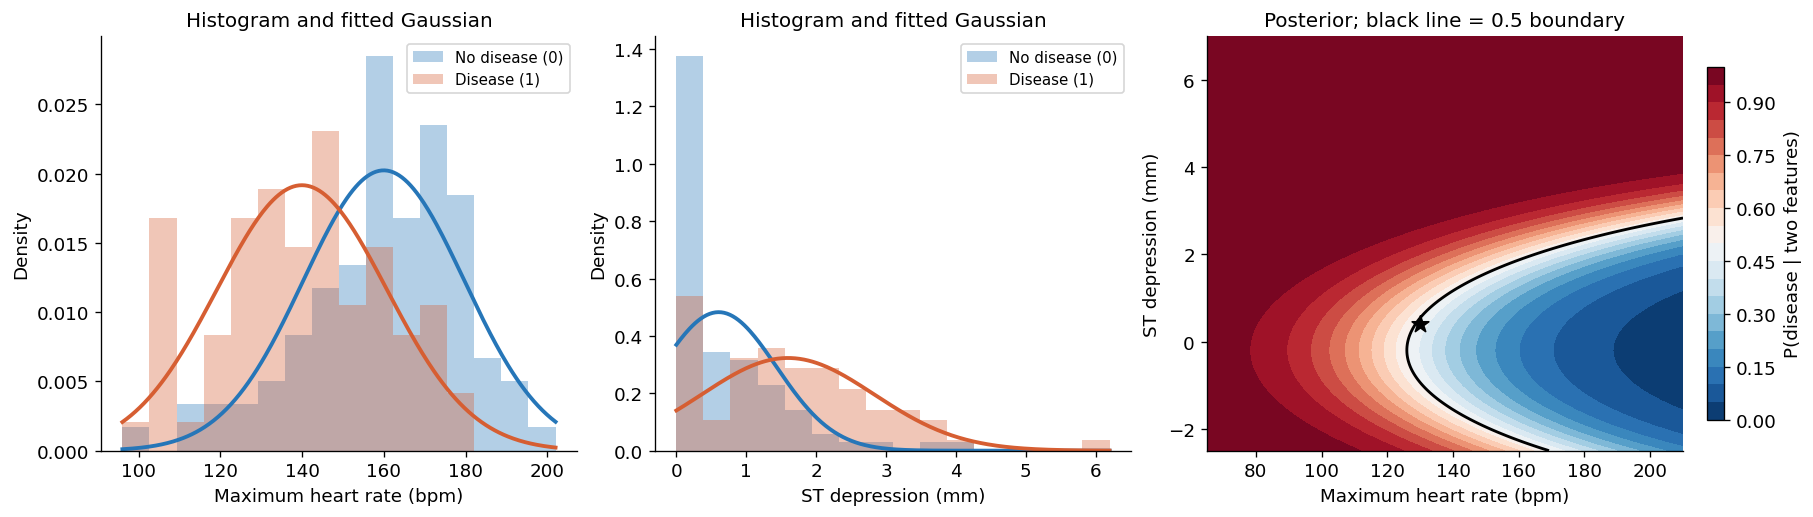

In [6]:
j_hr, j_st = 3, 4  # Maximum heart rate and ST depression inside X_cont.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), layout='constrained')
for ax, j, label in zip(axes[:2], [j_hr, j_st], ['Maximum heart rate (bpm)', 'ST depression (mm)']):
    values = X_cont[train_idx, j]
    edges = np.histogram_bin_edges(values, bins=16)
    xs = np.linspace(edges[0], edges[-1], 300)
    for c, color in enumerate(COLORS):
        ax.hist(values[y[train_idx] == c], bins=edges, density=True, alpha=0.35,
                color=color, label=CLASS_NAMES[c])
        ax.plot(xs, norm.pdf(xs, gnb_demo.theta_[c, j], np.sqrt(gnb_demo.var_[c, j])), color=color, lw=2.3)
    ax.set(xlabel=label, ylabel='Density', title='Histogram and fitted Gaussian')
    ax.legend(fontsize=9)

# A meshgrid evaluates the two-feature posterior at many possible readings.
gnb_pair = GaussianNB().fit(X_cont[train_idx][:, [j_hr, j_st]], y[train_idx])
xx, yy = np.meshgrid(np.linspace(65, 210, 200), np.linspace(-2.5, 7, 200))
posterior_grid = gnb_pair.predict_proba(np.column_stack([xx.ravel(), yy.ravel()]))[:, 1].reshape(xx.shape)
image = axes[2].contourf(xx, yy, posterior_grid, levels=np.linspace(0, 1, 21), cmap='RdBu_r', vmin=0, vmax=1)
axes[2].contour(xx, yy, posterior_grid, levels=[0.5], colors='black', linewidths=1.7)
axes[2].scatter(*new_cont[0, [j_hr, j_st]], s=110, marker='*', color='black')
axes[2].set(title='Posterior; black line = 0.5 boundary',
            xlabel='Maximum heart rate (bpm)', ylabel='ST depression (mm)')
fig.colorbar(image, ax=axes[2], label='P(disease | two features)', shrink=0.85)
plt.show()

## 5. Categorical and binary features
### Categorical NB: one probability table per feature
For category $k$ of categorical feature $j$,

$$P(x_j=k\mid y=c)=\frac{N_{cjk}+\alpha}{N_c+\alpha K_j}.$$

| Symbol | Attribute | Meaning here |
|---|---|---|
| $j$ | column of `X_cat` | 0 chest pain, 1 resting ECG, 2 ST slope, 3 major vessels, 4 thal |
| $K_j$ | `min_categories[j]` | Number of categories: 4, 3, 3, 4, 3 |
| $N_c$ | `class_count_[c]` | Training patients in class $c$: 90 and 72 |
| $N_{cjk}$ | `category_count_[j][c, k]` | Training patients of class $c$ whose feature $j$ is category $k$ |
| $P(x_j=k\mid y=c)$ | `np.exp(feature_log_prob_[j][c, k])` | The smoothed table entry |

`feature_log_prob_` is a list of 5 arrays, one per feature; array $j$ has shape
$(2, K_j)$ and each row sums to 1.

**Why smoothing?** The table entries are estimated by counting, and with few patients a
rare category can have a count of 0 in one class just by chance. Resting ECG = *ST-T
abnormality* ($j=1$, $k=1$) occurs in only 2 of the 270 patients. In our training rows it
appears once among the 72 patients with disease and never among the 90 without, so
without smoothing

$$P(\text{ST-T}\mid\text{no disease})=\frac{0}{90}=0,$$

which claims that a patient without heart disease *cannot* have this ECG. In Naive Bayes
this is fatal: the likelihood is a **product** over all features, so a single factor 0
makes $p(x\mid\text{no disease})=0$, whatever the other 12 features say. Every future
patient with this ECG would get $P(\text{disease}\mid x)=1$, on the strength of one
training patient.

**The fix: pretend that every category was seen $\alpha$ more times in every class**
($\alpha$ "pseudo-patients" per cell of the table). That is the $+\alpha$ in the numerator;
the denominator grows by $\alpha K_j$ because all $K_j$ cells receive $\alpha$. A category
with count 0 becomes rare but possible, and categories with many patients barely change.
$\alpha=1$ is called Laplace (add-one) smoothing. The code below shows the effect on
resting ECG; its tables are explained after it.

**Two different hyperparameters:** $\alpha$ smooths the feature probabilities; the
class prior $\pi_c$ is the probability of each class before seeing any features.

In [7]:
def smoothed_category_probabilities(counts, alpha):
    """Add alpha to each category and renormalize each class row."""
    K = counts.shape[1]
    return (counts + alpha) / (counts.sum(axis=1, keepdims=True) + alpha * K)

# N_cjk for j = 1 (resting ECG): rows = class c, columns = category k.
ecg_counts = np.array([np.bincount(X_cat[train_idx][y[train_idx] == c, 1], minlength=3) for c in [0, 1]])
display(pd.DataFrame(ecg_counts, index=CLASS_NAMES,
                     columns=['k=0: normal', 'k=1: ST-T abnormality', 'k=2: LV hypertrophy']))

rows = []
for alpha in [0.0, 1.0, 10.0, 100.0]:
    probability = smoothed_category_probabilities(ecg_counts, alpha)
    joint = 0.5 * probability[:, 1]  # Equal class priors; observe only ST-T abnormality.
    rows.append({'alpha': alpha,
                 'P(normal | no disease)': probability[0, 0], 'P(ST-T | no disease)': probability[0, 1],
                 'P(LV hypertrophy | no disease)': probability[0, 2],
                 'P(ST-T | disease)': probability[1, 1], 'P(disease | ST-T)': joint[1] / joint.sum()})
display(pd.DataFrame(rows).set_index('alpha').round(3))

,k=0: normal,k=1: ST-T abnormality,k=2: LV hypertrophy
No disease (0),49,0,41
Disease (1),24,1,47


,P(normal | no disease),P(ST-T | no disease),P(LV hypertrophy | no disease),P(ST-T | disease),P(disease | ST-T)
alpha,,,,,
0.0,0.544,0.000,0.456,0.014,1.000
1.0,0.538,0.011,0.452,0.027,0.713
10.0,0.492,0.083,0.425,0.108,0.564
100.0,0.382,0.256,0.362,0.272,0.514


**Reading the two tables.** The first table holds the training counts $N_{c,1,k}$ of
resting ECG. The second applies the smoothing formula for several values of $\alpha$. The
three "no disease" columns of a row form one smoothed distribution and sum to 1. The last
column is the posterior from this one feature alone, with equal priors, so that only the
ECG evidence counts.

*$\alpha=1$ step by step, for the patients without disease* ($N_0=90$, $K=3$):

| | normal | ST-T | LV hypertrophy | total |
|---|---:|---:|---:|---:|
| training count | 49 | 0 | 41 | 90 |
| plus $\alpha=1$ pseudo-patient in each cell | 50 | 1 | 42 | 93 |
| probability without smoothing | 49/90 = 0.544 | 0/90 = **0** | 41/90 = 0.456 | 1 |
| probability with $\alpha=1$ | 50/93 = 0.538 | 1/93 = **0.011** | 42/93 = 0.452 | 1 |

The common categories hardly move, while the 0 becomes small but positive. For the
patients with disease, $P(\text{ST-T}\mid\text{disease})=(1+1)/(72+3)=0.027$, so

$$P(\text{disease}\mid\text{ST-T})=\frac{0.5\cdot0.027}{0.5\cdot0.027+0.5\cdot0.011}=0.71$$

instead of 1.

*Larger $\alpha$:* the pseudo-patients start to outweigh the real ones. With $\alpha=100$
there are 300 pseudo-patients against 90 real ones, the three probabilities approach
$1/K=1/3$, and $P(\text{disease}\mid\text{ST-T})=0.51$: the feature has almost no influence
left. In general, the smoothed probability is a weighted average of the observed fraction
and the uniform value:

$$\frac{N_{cjk}+\alpha}{N_c+\alpha K_j}=w\,\frac{N_{cjk}}{N_c}+(1-w)\,\frac{1}{K_j},
\qquad w=\frac{N_c}{N_c+\alpha K_j},$$

where $w$ is the weight on the data. For the 90 patients without disease, $w$ = 1, 0.97,
0.75, and 0.23 for $\alpha$ = 0, 1, 10, and 100, and the more patients a class has, the
less smoothing changes. Too small an $\alpha$ overreacts to rare counts; too large an
$\alpha$ erases the feature. $\alpha$ is therefore a hyperparameter, chosen on the
validation set in Part 7.

#### Fit Categorical NB on all five categorical features
```python
model = CategoricalNB(alpha=1.0, class_prior=None, min_categories=[4, 3, 3, 4, 3])
model.fit(X_train_category_positions, y_train)
```
`min_categories` declares $K_j$, so a category missing from the training rows still gets
a smoothed probability. The first table lists $N_{0jk}$, $N_{1jk}$, and the table entries for
every feature $j$ and category $k$. The next two tables carry the new patient through to
the prediction, as in Part 4; they are explained below.

In [8]:
cat_demo = CategoricalNB(alpha=1.0, min_categories=category_sizes)
cat_demo.fit(X_cat[train_idx], y[train_idx])

def categorical_log_likelihood(model, X):
    """Look up one category probability per feature, then add the log values."""
    X = np.asarray(X, dtype=int)
    scores = np.zeros((len(X), len(model.classes_)))
    for j, log_table in enumerate(model.feature_log_prob_):
        scores += log_table[:, X[:, j]].T
    return scores  # Prior intentionally excluded so it can be added exactly once.

rows = []
for j, meanings in enumerate(categorical.values()):
    counts = cat_demo.category_count_[j]                 # N_cjk, shape (2, K_j)
    probability = np.exp(cat_demo.feature_log_prob_[j])  # P(x_j = k | c), shape (2, K_j)
    assert np.allclose(probability, smoothed_category_probabilities(counts, cat_demo.alpha))
    for k, meaning in enumerate(meanings.values()):
        rows.append({'feature j': f'{j}: {feature_names[5 + j]}', 'category k': f'{k}: {meaning}',
                     'N_0jk': int(counts[0, k]), 'N_1jk': int(counts[1, k]),
                     'P(k | no disease)': probability[0, k], 'P(k | disease)': probability[1, k]})
display(pd.DataFrame(rows).set_index(['feature j', 'category k']).round(3))

new_cat = new_patient[:, cols_cat].astype(int)
# New patient: the category k of each feature j selects one table entry per class c.
per_feature = np.array([log_table[:, k] for log_table, k
                        in zip(cat_demo.feature_log_prob_, new_cat[0])]).T  # log P(x_j = k | c), shape (2, 5)
contribution = per_feature[1] - per_feature[0]                            # Positive = favors disease.
display(pd.DataFrame({
    'category k': [f'{k}: {list(meanings.values())[k]}' for k, meanings in zip(new_cat[0], categorical.values())],
    'P(x_j=k | c=0)': np.exp(per_feature[0]), 'P(x_j=k | c=1)': np.exp(per_feature[1]),
    'log P(x_j=k | c=0)': per_feature[0], 'log P(x_j=k | c=1)': per_feature[1],
    'contribution': contribution
}, index=pd.Index([f'{j}: {name}' for j, name in enumerate(feature_names[5:10])], name='feature j')).round(3))

# From the five features to the prediction, exactly as in Part 4.
log_likelihood = per_feature.sum(axis=1)                # Naive assumption: add the five log probabilities.
log_prior = cat_demo.class_log_prior_
scores = log_likelihood + log_prior                    # s_0, s_1
posterior = probabilities_from_scores(scores[None])[0]  # P(c | x)
summary = pd.DataFrame({'c=0: no disease': [log_likelihood[0], log_prior[0], scores[0], posterior[0]],
                        'c=1: disease': [log_likelihood[1], log_prior[1], scores[1], posterior[1]]},
                       index=['log likelihood: sum_j log P(x_j | c)', 'log prior: log pi_c',
                              'score s_c', 'posterior P(c | x)'])
summary['c=1 minus c=0'] = summary['c=1: disease'] - summary['c=0: no disease']
summary.loc['posterior P(c | x)', 'c=1 minus c=0'] = np.nan
display(summary.round(3))

y_hat = scores.argmax()
print(f'Prediction: y_hat = argmax_c s_c = {y_hat} ({CLASS_NAMES[y_hat]}), P(disease | x) = {posterior[1]:.4f}')
print('scikit-learn predict_proba:', cat_demo.predict_proba(new_cat).round(4))
assert np.allclose(log_likelihood, categorical_log_likelihood(cat_demo, new_cat)[0])  # Same as the lookup function.
assert np.allclose(posterior, cat_demo.predict_proba(new_cat)[0])                    # Same as scikit-learn.

N_0jk  N_1jk  P(k | no disease)  \
feature j        category k                                              
0: chest pain    0: typical angina        12      4              0.138   
                 1: atypical angina       25      4              0.277   
                 2: non-anginal pain      41     11              0.447   
                 3: asymptomatic          12     53              0.138   
1: resting ECG   0: normal                49     24              0.538   
                 1: ST-T abnormality       0      1              0.011   
                 2: LV hypertrophy        41     47              0.452   
2: ST slope      0: upsloping             65     17              0.710   
                 1: flat                  19     49              0.215   
                 2: downsloping            6      6              0.075   
3: major vessels 0: 0                     68     25              0.734   
                 1: 1                     15     22              0.170   
                 2: 2                      6     14              0.074   
                 3: 3                      1     11              0.021   
4: thal          0: normal                74     20              0.806   
                 1: fixed defect           1      6              0.022   
                 2: reversible defect     15     46              0.172   

                                       P(k | disease)  
feature j        category k                            
0: chest pain    0: typical angina              0.066  
                 1: atypical angina             0.066  
                 2: non-anginal pain            0.158  
                 3: asymptomatic                0.711  
1: resting ECG   0: normal                      0.333  
                 1: ST-T abnormality            0.027  
                 2: LV hypertrophy              0.640  
2: ST slope      0: upsloping                   0.240  
                 1: flat                        0.667  
                 2: downsloping                 0.093  
3: major vessels 0: 0                           0.342  
                 1: 1                           0.303  
                 2: 2                           0.197  
                 3: 3                           0.158  
4: thal          0: normal                      0.280  
                 1: fixed defect                0.093  
                 2: reversible defect           0.627

,category k,P(x_j=k | c=0),P(x_j=k | c=1),log P(x_j=k | c=0),log P(x_j=k | c=1),contribution
feature j,,,,,,
0: chest pain,2: non-anginal pain,0.447,0.158,-0.806,-1.846,-1.040
1: resting ECG,2: LV hypertrophy,0.452,0.640,-0.795,-0.446,0.349
2: ST slope,0: upsloping,0.710,0.240,-0.343,-1.427,-1.084
3: major vessels,1: 1,0.170,0.303,-1.771,-1.195,0.575
4: thal,0: normal,0.806,0.280,-0.215,-1.273,-1.058


,c=0: no disease,c=1: disease,c=1 minus c=0
log likelihood: sum_j log P(x_j | c),-3.929,-6.187,-2.258
log prior: log pi_c,-0.588,-0.811,-0.223
score s_c,-4.517,-6.998,-2.481
posterior P(c | x),0.923,0.077,NaN


Prediction: y_hat = argmax_c s_c = 0 (No disease (0)), P(disease | x) = 0.0772
scikit-learn predict_proba: [[0.9228 0.0772]]


**Reading the new-patient tables.** For each feature $j$, the patient's category $k$ picks
one row of the big table above, which gives $P(x_j=k\mid c)$ for both classes: nothing is
computed, only looked up. As in Part 4, the **contribution** is
$\log P(x_j=k\mid 1)-\log P(x_j=k\mid 0)$; positive pushes toward disease, negative toward
no disease.

*Example, chest pain = non-anginal pain* ($k=2$): the big table gives 0.447 without and
0.158 with disease, so $\log 0.447=-0.806$, $\log 0.158=-1.846$, and the contribution is
$-1.846-(-0.806)=-1.040$. Non-anginal pain is almost three times as common among the
patients without disease.

The second table follows the same four steps as in Part 4:

1. **Log likelihood**: $\sum_j\log P(x_j\mid c)$ over the five features: $-3.929$ for no
   disease and $-6.187$ for disease.
2. **Log prior**: $-0.588$ and $-0.811$, as in Part 4.
3. **Score**: $s_0=-4.517$ and $s_1=-6.998$. This time the larger score belongs to no
   disease, so $\hat y=0$.
4. **Posterior**: the scores differ by $-2.481$, so
   $P(\text{disease}\mid x)=1/(1+e^{2.481})=0.077$.

Three of the five features (chest pain, ST slope, thal) point clearly toward no disease,
so the categorical block disagrees with the continuous block of Part 4 ($P=0.72$).

### Bernoulli NB: presence and absence are both evidence
For binary feature $j$, let $q_{cj}=P(x_j=1\mid y=c)$. Then

$$\log P(x_j\mid y=c)=x_j\log q_{cj}+(1-x_j)\log(1-q_{cj}),\qquad
q_{cj}=\frac{N_{cj}^{(1)}+\alpha}{N_c+2\alpha}.$$

| Symbol | Attribute | Meaning here |
|---|---|---|
| $j$ | column of `X_bin` | 0 male, 1 fasting blood sugar > 120, 2 exercise angina |
| $N^{(1)}_{cj}$ | `feature_count_[c, j]` | Training patients of class $c$ with feature $j$ = 1 |
| $q_{cj}$ | `np.exp(feature_log_prob_[c, j])` | Smoothed $P(x_j=1\mid y=c)$; shape (2, 3) |

No exercise angina contributes $\log(1-q_{cj})$; it is not ignored. In the second table,
a patient with all three flags 0 gets a lower $P(\text{disease})$ than the 44% prior.

```python
model = BernoulliNB(alpha=1.0, binarize=None)   # binarize=None: inputs are already 0/1
model.fit(X_train_binary, y_train)
```

**Bernoulli NB vs Categorical NB.**

| | Categorical NB | Bernoulli NB |
|---|---|---|
| Values of a feature | one of $K_j$ categories | 0 or 1 |
| Parameters per feature and class | a table of $K_j$ probabilities that sum to 1 | one number $q_{cj}$; then $P(x_j=0\mid c)=1-q_{cj}$ |
| Smoothing | $(N_{cjk}+\alpha)/(N_c+\alpha K_j)$ | $(N^{(1)}_{cj}+\alpha)/(N_c+2\alpha)$ |
| `feature_log_prob_` | a list of arrays of shape $(2, K_j)$ | one array of shape $(2, d)$ holding $\log q_{cj}$ |

For a binary feature the two are the **same model**: Bernoulli NB is Categorical NB with
$K_j=2$ and gives exactly the same probabilities. Bernoulli NB is simply convenient when
there are many 0/1 features, e.g. which words appear in an email. Do **not** one-hot encode
a categorical feature into several 0/1 columns for Bernoulli NB: those columns are not
independent (exactly one of them is 1), so Bernoulli NB would also count the absence of
every other category as evidence and become overconfident.

The last two tables carry the new patient through to the prediction, as in Part 4; they
are explained below.

In [9]:
bin_demo = BernoulliNB(alpha=1.0, binarize=None).fit(X_bin[train_idx], y[train_idx])
q = np.exp(bin_demo.feature_log_prob_)  # q_cj, shape (2, 3)
N1 = bin_demo.feature_count_            # N_cj^(1), shape (2, 3)
assert np.allclose(q, (N1 + bin_demo.alpha) / (bin_demo.class_count_[:, None] + 2 * bin_demo.alpha))
display(pd.DataFrame({'N_0j^(1)': N1[0].astype(int), 'N_1j^(1)': N1[1].astype(int),
                      'q_0j': q[0], 'q_1j': q[1]},
                     index=pd.Index([f'{j}: {name}' for j, name in enumerate(feature_names[10:])],
                                    name='feature j')).round(3))

def bernoulli_log_likelihood(model, X):
    """Include log probabilities of both present and absent binary features."""
    X = np.asarray(X)
    q = np.exp(model.feature_log_prob_)
    return X @ np.log(q).T + (1 - X) @ np.log1p(-q).T

# All 2^3 = 8 combinations of the three flags.
binary_probes = np.array([[a, b, c] for a in [0, 1] for b in [0, 1] for c in [0, 1]])
posterior = probabilities_from_scores(bernoulli_log_likelihood(bin_demo, binary_probes) + bin_demo.class_log_prior_)
assert np.allclose(posterior, bin_demo.predict_proba(binary_probes))
probe_table = pd.DataFrame(binary_probes, columns=feature_names[10:])
probe_table['P(disease)'] = posterior[:, 1]
display(probe_table.round(3))

new_bin = new_patient[:, cols_bin]
# New patient: P(x_j | c) is q_cj if x_j = 1 and 1 - q_cj if x_j = 0; both cases are evidence.
probability_used = np.where(new_bin[0] == 1, q, 1 - q)  # Shape (2, 3).
per_feature = np.log(probability_used)                  # log P(x_j | c)
contribution = per_feature[1] - per_feature[0]          # Positive = favors disease.
display(pd.DataFrame({
    'x_j': new_bin[0].astype(int), 'uses': np.where(new_bin[0] == 1, 'q', '1 - q'),
    'P(x_j | c=0)': probability_used[0], 'P(x_j | c=1)': probability_used[1],
    'log P(x_j | c=0)': per_feature[0], 'log P(x_j | c=1)': per_feature[1],
    'contribution': contribution
}, index=pd.Index([f'{j}: {name}' for j, name in enumerate(feature_names[10:])], name='feature j')).round(3))

# From the three features to the prediction, exactly as in Part 4.
log_likelihood = per_feature.sum(axis=1)                # Naive assumption: add the three log probabilities.
log_prior = bin_demo.class_log_prior_
scores = log_likelihood + log_prior                    # s_0, s_1
posterior = probabilities_from_scores(scores[None])[0]  # P(c | x)
summary = pd.DataFrame({'c=0: no disease': [log_likelihood[0], log_prior[0], scores[0], posterior[0]],
                        'c=1: disease': [log_likelihood[1], log_prior[1], scores[1], posterior[1]]},
                       index=['log likelihood: sum_j log P(x_j | c)', 'log prior: log pi_c',
                              'score s_c', 'posterior P(c | x)'])
summary['c=1 minus c=0'] = summary['c=1: disease'] - summary['c=0: no disease']
summary.loc['posterior P(c | x)', 'c=1 minus c=0'] = np.nan
display(summary.round(3))

y_hat = scores.argmax()
print(f'Prediction: y_hat = argmax_c s_c = {y_hat} ({CLASS_NAMES[y_hat]}), P(disease | x) = {posterior[1]:.4f}')
print('scikit-learn predict_proba:', bin_demo.predict_proba(new_bin).round(4))
assert np.allclose(log_likelihood, bernoulli_log_likelihood(bin_demo, new_bin)[0])  # Same as the function.
assert np.allclose(posterior, bin_demo.predict_proba(new_bin)[0])                    # Same as scikit-learn.

,N_0j^(1),N_1j^(1),q_0j,q_1j
feature j,,,,
0: male,47,60,0.522,0.824
1: fasting blood sugar > 120,15,10,0.174,0.149
2: exercise angina,11,39,0.130,0.541


,male,fasting blood sugar > 120,exercise angina,P(disease)
0,0,0,0,0.138
1,0,0,1,0.557
2,0,1,0,0.117
3,0,1,1,0.510
4,1,0,0,0.408
5,1,0,1,0.844
6,1,1,0,0.363
7,1,1,1,0.817


,x_j,uses,P(x_j | c=0),P(x_j | c=1),log P(x_j | c=0),log P(x_j | c=1),contribution
feature j,,,,,,,
0: male,1,q,0.522,0.824,-0.651,-0.193,0.457
1: fasting blood sugar > 120,0,1 - q,0.826,0.851,-0.191,-0.161,0.030
2: exercise angina,1,q,0.130,0.541,-2.037,-0.615,1.422


,c=0: no disease,c=1: disease,c=1 minus c=0
log likelihood: sum_j log P(x_j | c),-2.879,-0.969,1.909
log prior: log pi_c,-0.588,-0.811,-0.223
score s_c,-3.466,-1.780,1.686
posterior P(c | x),0.156,0.844,NaN


Prediction: y_hat = argmax_c s_c = 1 (Disease (1)), P(disease | x) = 0.8437
scikit-learn predict_proba: [[0.1563 0.8437]]


**Reading the new-patient tables.** A binary feature has a single parameter per class,
$q_{cj}=P(x_j=1\mid c)$, taken from the $q$ table above. The column *uses* shows which
probability the patient's value selects: $q_{cj}$ if the flag is present ($x_j=1$), and
$1-q_{cj}$ if it is absent ($x_j=0$). The contribution is again
$\log P(x_j\mid 1)-\log P(x_j\mid 0)$.

- *Exercise angina = 1* uses $q$: 0.130 without and 0.541 with disease, so the contribution
  is $\log 0.541-\log 0.130=-0.615-(-2.037)=1.422$, the strongest of the three. Angina
  during the test is about four times as common among the patients with disease.
- *Fasting blood sugar = 0* uses $1-q$: $1-0.174=0.826$ and $1-0.149=0.851$. The absence
  of the flag still enters the product, but the two classes are nearly equal, so its
  contribution is only $+0.030$.

The second table follows the same four steps as in Part 4: log likelihoods $-2.879$ and
$-0.969$, log priors $-0.588$ and $-0.811$, scores $s_0=-3.466$ and $s_1=-1.780$. So
$\hat y=1$ (disease), and $P(\text{disease}\mid x)=1/(1+e^{-1.686})=0.844$.

## 6. All feature types together: Mixed NB
Under the same conditional independence assumption, the log likelihoods of the three
blocks add up:

$$s_c(x)=\log\pi_c
+\sum_{j\in\text{cont}}\log p_G(x_j\mid c)
+\sum_{j\in\text{cat}}\log P_C(x_j\mid c)
+\sum_{j\in\text{bin}}\log P_B(x_j\mid c).$$

The class below fits one model per block, adds their **likelihood** terms, and adds the
log prior **once**. Multiplying the three models' posteriors would be wrong, because
each posterior already contains the prior. ("Mixed" means mixed feature types, not a
Gaussian mixture model.)

| Attribute | `X_mixed` columns | Features | Parameters inside |
|---|---|---|---|
| `gaussian_` | 0–4 | age, resting BP, cholesterol, max heart rate, ST depression | `theta_`, `var_` (Part 4) |
| `categorical_` | 5–9 | chest pain, resting ECG, ST slope, major vessels, thal | 5 tables (Part 5) |
| `binary_` | 10–12 | male, fasting blood sugar > 120, exercise angina | $q$ (Part 5) |
| `log_prior_` | | | $\log\pi_c$ |

For the new patient the blocks disagree: the continuous and binary features point
toward disease, the categorical features toward no disease. In the table, compare the
two classes within a column (last row), not one column with another: a log density can
have any sign and depends on the features' units.

In [10]:
class MixedNaiveBayes:
    """Gaussian NB on cont_cols, categorical NB on cat_cols, Bernoulli NB on bin_cols.
    The defaults are the heart-data columns from Part 1."""

    def __init__(self, alpha=1.0, priors=None, cont_cols=cols_cont, cat_cols=cols_cat,
                 bin_cols=cols_bin, n_categories=category_sizes):
        self.alpha = alpha
        self.priors = priors
        self.cont_cols, self.cat_cols, self.bin_cols = list(cont_cols), list(cat_cols), list(bin_cols)
        self.n_categories = n_categories  # Known number of categories of each categorical column.

    def fit(self, X, y):
        X = np.asarray(X)
        self.classes_, counts = np.unique(y, return_counts=True)
        prior = counts / counts.sum() if self.priors is None else np.asarray(self.priors, dtype=float)
        self.log_prior_ = np.log(prior)
        self.gaussian_ = GaussianNB().fit(X[:, self.cont_cols], y)
        self.categorical_ = CategoricalNB(
            alpha=self.alpha, min_categories=np.asarray(self.n_categories)
        ).fit(X[:, self.cat_cols].astype(int), y)
        self.binary_ = BernoulliNB(alpha=self.alpha, binarize=None).fit(X[:, self.bin_cols], y)
        return self

    def evidence(self, X):
        """Return separate log-likelihood blocks; no block contains a prior."""
        X = np.asarray(X)
        return {
            'Gaussian evidence': gaussian_log_likelihood(self.gaussian_, X[:, self.cont_cols]),
            'Categorical evidence': categorical_log_likelihood(self.categorical_, X[:, self.cat_cols]),
            'Binary evidence': bernoulli_log_likelihood(self.binary_, X[:, self.bin_cols])
        }

    def predict_proba(self, X):
        blocks = self.evidence(X)
        scores = sum(blocks.values()) + self.log_prior_
        return probabilities_from_scores(scores)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

mixed_demo = MixedNaiveBayes().fit(X_mixed[train_idx], y[train_idx])
contributions = pd.DataFrame({name: score[0] for name, score in mixed_demo.evidence(new_patient).items()},
                             index=CLASS_NAMES)
contributions['Log prior'] = mixed_demo.log_prior_
contributions['Total score'] = contributions.sum(axis=1)
contributions['Posterior'] = mixed_demo.predict_proba(new_patient)[0]
# Last row: disease minus no disease. Positive = favors disease.
contributions.loc['Difference'] = contributions.iloc[1] - contributions.iloc[0]
contributions.loc['Difference', 'Posterior'] = np.nan
display(contributions.round(3))

,Gaussian evidence,Categorical evidence,Binary evidence,Log prior,Total score,Posterior
No disease (0),-19.150,-3.929,-2.879,-0.588,-26.545,0.353
Disease (1),-17.972,-6.187,-0.969,-0.811,-25.939,0.647
Difference,1.178,-2.258,1.909,-0.223,0.606,NaN


## 7. Choose α and the prior on the validation set
A model has two kinds of numbers.

**Parameters** are learned by `fit` from the training rows with a closed-form formula
(counts, averages, variances). We never choose or tune them by hand: once the training
rows and the hyperparameters are fixed, the parameters are fixed too.

| Model | Parameters (Parts 4 to 6) | Attribute | How many |
|---|---|---|---:|
| Gaussian NB | $\mu_{cj}$ and $\sigma^2_{cj}$ of the 5 continuous features | `theta_`, `var_` | 20 |
| Categorical NB | table entries $P(x_j=k\mid c)$ of the 5 categorical features | `feature_log_prob_` (5 tables) | 34 |
| Bernoulli NB | $q_{cj}$ of the 3 binary features | `feature_log_prob_` | 6 |
| Mixed NB | all of the above | `gaussian_`, `categorical_`, `binary_` | 60 |
| every model | class prior $\pi_c$, when it is estimated from the data | `class_prior_`, `log_prior_` | 2 |

**Hyperparameters** are set by us *before* `fit`. Training cannot learn them, so the
validation set chooses them:

| Hyperparameter | Affects | Candidates |
|---|---|---|
| $\alpha$ (`alpha`) | The 5 categorical tables and the 3 binary $q$'s (one shared $\alpha$ in Mixed NB); Gaussian NB has none | 0.01, 0.1, 0.5, 1, 5, 20, 100 |
| prior $\pi_1=P(\text{disease})$ (`positive_prior`) | No feature: it shifts every patient's log odds by the same $\log(\pi_1/\pi_0)$ | empirical (`None`, 44%), 0.15, 0.30, 0.50, 0.70 |

Two remarks on the tables:
- The **prior** appears in both. The candidate "empirical" (`None`) means "estimate
  $\pi_c$ from the training rows", i.e. a parameter; the other candidates fix it by hand.
- $\alpha$ enters the formula of the tables, $(N_{cjk}+\alpha)/(N_c+\alpha K_j)$, but it is
  still a hyperparameter: the counts $N$ come from the data, while $\alpha$ is our choice of
  *how much* to trust them. (`GaussianNB` also has `var_smoothing`, a tiny constant added
  to the variances; we keep its default.)
- Mixed NB uses **one** $\alpha$ for its categorical and binary blocks. Separate values
  ($7\times7$ combinations) were also tried: validation picks $\alpha=20$ for both, so one
  shared $\alpha$ loses nothing here. The binary block on its own (Bernoulli NB) prefers
  $\alpha=5$, so the best $\alpha$ of a block depends on the rest of the model.

For every model and setting: fit on **train**, score on **validation**. Each model keeps
the setting with the lowest validation **log loss**, and the model with the lowest
validation log loss becomes the final model. The test rows are not used.

$$\text{log loss}=-\frac{1}{m}\sum_{i=1}^{m}\log P(y_i\mid x_i).$$

Log loss rewards good probabilities, not only correct labels, and penalizes confident
mistakes heavily. Accuracy on 54 patients moves in steps of 1/54, so many settings tie.

In [11]:
ALPHAS = [0.01, 0.1, 0.5, 1.0, 5.0, 20.0, 100.0]
POSITIVE_PRIORS = [None, 0.15, 0.30, 0.50, 0.70]  # None = empirical prior of the fitting rows.

def prior_vector(positive_prior):
    """None = empirical prior; otherwise return [P(class 0), P(class 1)]."""
    return None if positive_prior is None else np.array([1 - positive_prior, positive_prior])

def evaluate(y_true, probability):
    """Accuracy uses the predicted labels; log loss uses the predicted probabilities."""
    return {'accuracy': accuracy_score(y_true, probability.argmax(axis=1)),
            'log loss': log_loss(y_true, probability, labels=[0, 1])}

def tune_on_validation(experiments, labels, fit_rows, val_rows):
    """Fit every setting on train and score it on validation; keep the fitted model with the lowest log loss."""
    best_settings, best_models, records = {}, {}, []
    for name, (X, grid, make_model) in experiments.items():
        scored, fitted = [], []
        for setting in grid:
            model = make_model(setting).fit(X[fit_rows], labels[fit_rows])          # Fit on train only.
            scores = evaluate(labels[val_rows], model.predict_proba(X[val_rows]))  # Score on validation.
            scored.append({'val ' + k: v for k, v in scores.items()})
            fitted.append(model)
        table = pd.DataFrame(scored)
        best = table['val log loss'].idxmin()
        best_settings[name], best_models[name] = grid[best], fitted[best]
        records.append({'model': name, 'selected settings': str(grid[best]),
                        **table.loc[best, ['val accuracy', 'val log loss']].to_dict()})
    results = pd.DataFrame(records)
    chosen = results.loc[results['val log loss'].idxmin(), 'model']
    return results, best_settings, best_models, chosen

prior_grid = [{'positive_prior': p} for p in POSITIVE_PRIORS]
alpha_prior_grid = [{'alpha': a, 'positive_prior': p} for a in ALPHAS for p in POSITIVE_PRIORS]

# name: (features, candidate settings, function that builds an unfitted model)
experiments = {
    'Gaussian NB': (X_cont, prior_grid,
                    lambda s: GaussianNB(priors=prior_vector(s['positive_prior']))),
    'Categorical NB': (X_cat, alpha_prior_grid,
                       lambda s: CategoricalNB(alpha=s['alpha'], min_categories=category_sizes,
                                               class_prior=prior_vector(s['positive_prior']))),
    'Bernoulli NB': (X_bin, alpha_prior_grid,
                     lambda s: BernoulliNB(alpha=s['alpha'], binarize=None,
                                           class_prior=prior_vector(s['positive_prior']))),
    'Mixed NB': (X_mixed, alpha_prior_grid,
                 lambda s: MixedNaiveBayes(alpha=s['alpha'], priors=prior_vector(s['positive_prior'])))
}

validation_results, best_settings, best_models, chosen_model = tune_on_validation(
    experiments, y, train_idx, val_idx)
display(validation_results.round(4))
print('Model chosen on validation:', chosen_model)
print('Test predictions have not been computed.')

,model,selected settings,val accuracy,val log loss
0,Gaussian NB,{'positive_prior': None},0.6667,0.6940
1,Categorical NB,"{'alpha': 20.0, 'positive_prior': None}",0.7963,0.4972
2,Bernoulli NB,"{'alpha': 5.0, 'positive_prior': None}",0.6852,0.5838
3,Mixed NB,"{'alpha': 20.0, 'positive_prior': None}",0.7407,0.6089


Model chosen on validation: Categorical NB
Test predictions have not been computed.


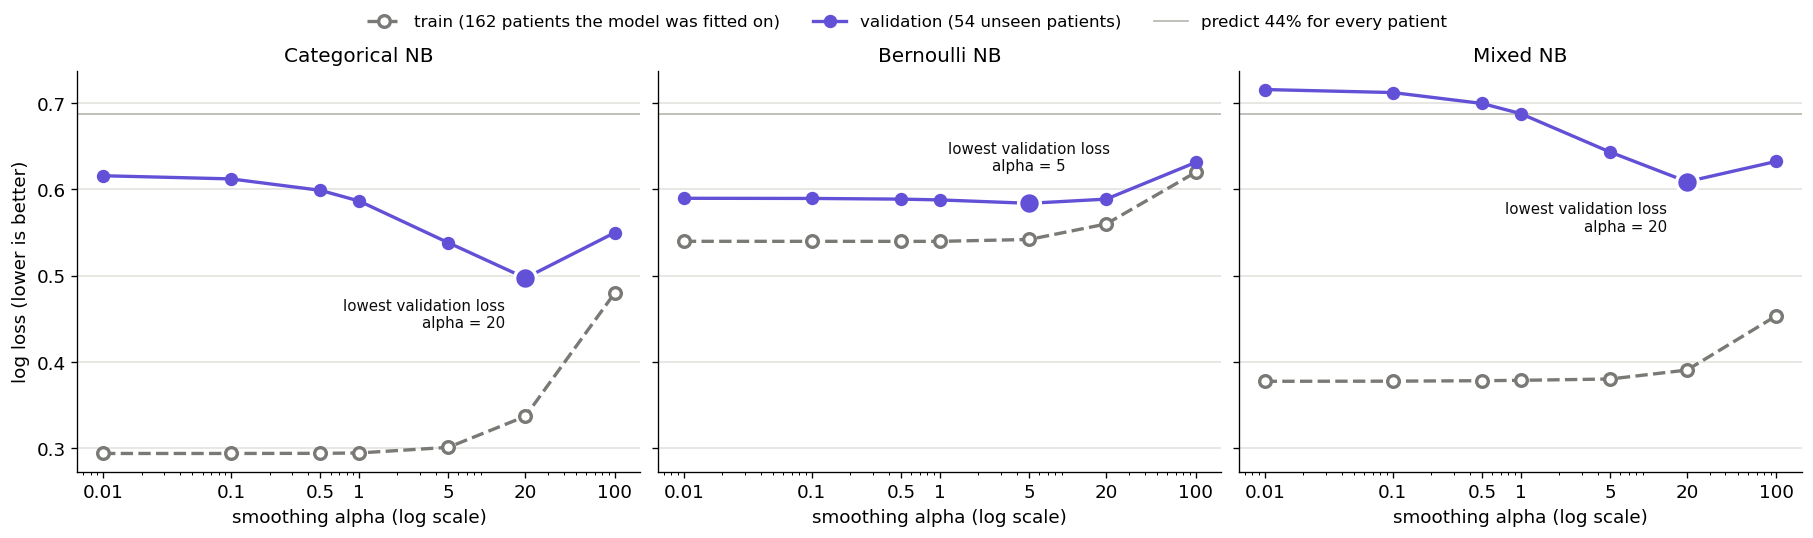

Categorical NB                       Bernoulli NB                      \
       train log loss validation log loss train log loss validation log loss   
alpha                                                                          
0.01            0.294               0.616          0.540               0.590   
0.10            0.294               0.612          0.540               0.589   
0.50            0.294               0.599          0.540               0.589   
1.00            0.294               0.587          0.540               0.588   
5.00            0.301               0.538          0.542               0.584   
20.00           0.337               0.497          0.560               0.589   
100.00          0.480               0.550          0.620               0.631   

             Mixed NB                      
       train log loss validation log loss  
alpha                                      
0.01            0.377               0.716  
0.10            0.378               0.712  
0.50            0.378               0.700  
1.00            0.379               0.688  
5.00            0.380               0.643  
20.00           0.391               0.609  
100.00          0.453               0.632

In [12]:
# Train and validation log loss along alpha (empirical prior) for the three models that have alpha.
TRAIN_COLOR, VAL_COLOR = '#7a7975', '#6250d6'
train_prior = np.bincount(y[train_idx]) / len(train_idx)
baseline = log_loss(y[val_idx], np.tile(train_prior, (len(val_idx), 1)))  # Predict 44% for everyone.

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True, layout='constrained')
curves = {}
for ax, name in zip(axes, ['Categorical NB', 'Bernoulli NB', 'Mixed NB']):
    X, grid, make_model = experiments[name]
    train_loss, val_loss = [], []
    for alpha in ALPHAS:
        model = make_model({'alpha': alpha, 'positive_prior': None}).fit(X[train_idx], y[train_idx])
        train_loss.append(log_loss(y[train_idx], model.predict_proba(X[train_idx])))  # Rows the model has seen.
        val_loss.append(log_loss(y[val_idx], model.predict_proba(X[val_idx])))        # Rows it has not seen.
    curves[name] = pd.DataFrame({'train log loss': train_loss, 'validation log loss': val_loss},
                                index=pd.Index(ALPHAS, name='alpha'))
    ax.plot(ALPHAS, train_loss, color=TRAIN_COLOR, lw=2, ls='--', marker='o', ms=7, mfc='white', mew=2,
            label='train (162 patients the model was fitted on)')
    ax.plot(ALPHAS, val_loss, color=VAL_COLOR, lw=2, marker='o', ms=7, label='validation (54 unseen patients)')
    ax.axhline(baseline, color='#b5b4ae', lw=1, zorder=0, label='predict 44% for every patient')
    best = int(np.argmin(val_loss))
    ax.scatter(ALPHAS[best], val_loss[best], s=170, color=VAL_COLOR, edgecolor='white', linewidth=2, zorder=3)
    room_below = val_loss[best] - train_loss[best] > 0.1  # Note below-left if the train curve is far below.
    ax.annotate(f'lowest validation loss\nalpha = {ALPHAS[best]:g}', (ALPHAS[best], val_loss[best]),
                xytext=(-12, -12) if room_below else (0, 18), textcoords='offset points',
                ha='right' if room_below else 'center', va='top' if room_below else 'bottom',
                fontsize=9, color='#0b0b0b')
    ax.set(xscale='log', xticks=ALPHAS, xticklabels=[f'{a:g}' for a in ALPHAS],
           xlabel='smoothing alpha (log scale)', title=name)
    ax.grid(axis='y', color='#e4e3df', lw=1)
axes[0].set_ylabel('log loss (lower is better)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside upper center', ncol=3, frameon=False, fontsize=10)
plt.show()
display(pd.concat(curves, axis=1).round(3))

**Reading the curves.** For every $\alpha$ (with the empirical prior), each panel fits the
model on the training rows and computes the log loss twice: on the same 162 training
patients (dashed) and on the 54 validation patients (solid). The table lists the values.

**What is the train loss?** Naive Bayes does not minimize a loss: `fit` only counts and
averages (Parts 4 and 5). The train loss is simply the log-loss formula above, evaluated
on the rows the model was fitted on. It measures how well the model describes data it
has already seen, which is always optimistic.

- **Train loss rises with $\alpha$.** With a small $\alpha$ the tables reproduce the
  training counts almost exactly, so the training patients look very predictable
  (Categorical NB: 0.294). A larger $\alpha$ pulls the tables away from those counts toward
  uniform, so they fit the training rows worse (0.480 at $\alpha=100$).
- **Validation loss is U-shaped.** Too small an $\alpha$: probabilities estimated from a
  handful of patients are too extreme and confidently wrong for new patients
  (*overfitting*; 0.616 at $\alpha=0.01$). Too large an $\alpha$: the tables become nearly
  uniform and the features lose their information (*underfitting*; 0.550 at
  $\alpha=100$). The marked minimum is the $\alpha$ selected in the table above (20).
- **The gap** between the two curves shows how optimistic the training rows are. Judged
  on them, the smallest $\alpha$ would always win; that is why hyperparameters are chosen
  on the validation set.
- **Bernoulli NB** has only 6 table parameters, each estimated from many patients, so
  smoothing hardly matters until $\alpha$ is large, and the gap is small.
- **Mixed NB** has the largest gap. For small $\alpha$ its validation loss is even above the
  gray line, i.e. worse than predicting 44% for every patient. $\alpha$ smooths only its
  categorical and binary blocks; the Gaussian block is unaffected, which is part of the
  overconfidence seen in Part 8.

The prior is the other hyperparameter. All four models chose the empirical prior (44%),
as expected when the validation patients have the same disease rate as the training
patients.

## 8. Report final test performance
All hyperparameters and the model choice are now frozen. Each model is used **exactly as
selected in Part 7**: fitted on the 162 training patients with its best setting, and not
retrained. It predicts the 54 test patients **once**. The reported result is the test
performance of the model chosen in Part 7; the other rows are for comparison only.

The table repeats each model's validation log loss, because every choice was made on
validation: the settings of all four models, and the final model (the lowest validation
log loss, Categorical NB). The test columns only report; they choose nothing, so a
model with a higher test accuracy does not replace the final model.

In [13]:
def report_on_test(best_models, experiments, best_settings, validation_results, chosen, labels, test_rows):
    """Predict the test rows once with each model selected on validation (no refitting)."""
    val_loss = validation_results.set_index('model')['val log loss']
    records, probabilities = [], {}
    for name, model in best_models.items():
        X = experiments[name][0]                                  # This model's feature columns.
        probabilities[name] = model.predict_proba(X[test_rows])  # The only use of the test rows.
        scores = evaluate(labels[test_rows], probabilities[name])
        records.append({'model': name, 'settings chosen on validation': str(best_settings[name]),
                        'val log loss': val_loss[name],
                        'final model (lowest val log loss)': name == chosen,
                        **{'test ' + k: v for k, v in scores.items()}})
    return pd.DataFrame(records), probabilities

test_results, test_probabilities = report_on_test(
    best_models, experiments, best_settings, validation_results, chosen_model, y, test_idx
)
display(test_results.round(4))
final = test_results.set_index('model').loc[chosen_model]
print(f"Final test performance of {chosen_model}: accuracy = {final['test accuracy']:.3f}, "
      f"log loss = {final['test log loss']:.3f}")

matrix = confusion_matrix(y[test_idx], test_probabilities[chosen_model].argmax(axis=1), labels=[0, 1])
display(pd.DataFrame(matrix, index=['true: no disease', 'true: disease'],
                     columns=['predicted: no disease', 'predicted: disease']))

# Accuracy vs log loss: how confident is each model on the test patients?
for name in ['Categorical NB', 'Mixed NB']:
    confidence = test_probabilities[name].max(axis=1)
    wrong = test_probabilities[name].argmax(axis=1) != y[test_idx]
    print(f'{name:15s} predictions above 0.95: {np.sum(confidence > 0.95):2d} of {len(test_idx)}; '
          f'mistakes: {wrong.sum()}, with average confidence {confidence[wrong].mean():.2f}')

,model,settings chosen on validation,val log loss,final model (lowest val log loss),test accuracy,test log loss
0,Gaussian NB,{'positive_prior': None},0.6940,False,0.7222,0.5217
1,Categorical NB,"{'alpha': 20.0, 'positive_prior': None}",0.4972,True,0.7963,0.4208
2,Bernoulli NB,"{'alpha': 5.0, 'positive_prior': None}",0.5838,False,0.7037,0.6171
3,Mixed NB,"{'alpha': 20.0, 'positive_prior': None}",0.6089,False,0.8148,0.4730


Final test performance of Categorical NB: accuracy = 0.796, log loss = 0.421


,predicted: no disease,predicted: disease
true: no disease,22,8
true: disease,3,21


Categorical NB  predictions above 0.95:  7 of 54; mistakes: 11, with average confidence 0.68
Mixed NB        predictions above 0.95: 32 of 54; mistakes: 10, with average confidence 0.78


**Reading the results.**

*Accuracy vs log loss.* Both are computed on the same 54 test patients, but they look at
different things:

| | Accuracy | Log loss |
|---|---|---|
| Uses | only the predicted label $\hat y=\arg\max_c P(c\mid x)$, i.e. whether $P(\text{disease}\mid x)>0.5$ | the predicted probability of the true class, $P(y_i\mid x_i)$ |
| One patient contributes | 1 if correct, 0 if wrong | $-\log P(y_i\mid x_i)$: 0.105 for 0.9, 0.693 for 0.5, 2.303 for 0.1 |
| Better | higher | lower |
| Blind to | how confident the prediction is: 0.51 and 0.99 count the same | nothing: every change of a probability changes it |

Mixed NB has the higher test accuracy (0.815 vs 0.796: 44 instead of 43 patients right)
but also the higher log loss (0.473 vs 0.421). Its probabilities are too extreme, and its
confident mistakes are punished heavily. For a diagnosis the probability itself matters,
which is why validation selects by log loss.

*Confusion matrix* of the chosen model (label = argmax, i.e. threshold 0.5): of the 24
test patients with disease, 21 are flagged and 3 are missed; of the 30 without disease,
22 are cleared and 8 are false alarms.

*Confidence.* The confidence of a prediction is the probability of the predicted class,
$\max_c P(c\mid x)$, which lies between 0.5 and 1 for two classes. "Above 0.95" is only a
reporting cutoff for "almost certain"; it is not a hyperparameter and changes no
prediction. The last two lines count, for each model, how many test patients get such
near-certain predictions, and how confident the model is on average on the patients it
gets wrong. Mixed NB is almost certain for 32 of the 54 patients (Categorical NB: 7), and
its average confidence on its mistakes is 0.78 (Categorical NB: 0.68). These confident
mistakes are what drive its log loss up.

In [14]:
# Where does the log loss come from? Group the test predictions by their confidence.
bins, bin_labels = [0.5, 0.7, 0.9, 0.95, 1.0], ['0.5-0.7', '0.7-0.9', '0.9-0.95', 'above 0.95']
tables = {}
for name in ['Categorical NB', 'Mixed NB']:
    probability = test_probabilities[name]
    confidence = probability.max(axis=1)                                 # Probability of the predicted class.
    correct = probability.argmax(axis=1) == y[test_idx]
    loss = -np.log(probability[np.arange(len(test_idx)), y[test_idx]])  # Each patient's log-loss term.
    group = pd.cut(confidence, bins, labels=bin_labels, include_lowest=True)
    tables[name] = pd.DataFrame({'group': group, 'correct': correct, 'loss': loss}).groupby(
        'group', observed=False).agg(predictions=('correct', 'size'),
                                     wrong=('correct', lambda s: int((~s).sum())),
                                     **{'fraction correct': ('correct', 'mean'),
                                        'sum of loss terms': ('loss', 'sum')})
    print(f'{name:15s} loss terms: {loss[correct].sum():5.2f} (correct) + {loss[~correct].sum():5.2f} (wrong) '
          f'= {loss.sum():5.2f};  / {len(test_idx)} = log loss {loss.mean():.3f}')
display(pd.concat(tables, axis=1).round(3))

Categorical NB  loss terms:  9.32 (correct) + 13.40 (wrong) = 22.72;  / 54 = log loss 0.421
Mixed NB        loss terms:  4.16 (correct) + 21.39 (wrong) = 25.54;  / 54 = log loss 0.473


Categorical NB                                           \
              predictions wrong fraction correct sum of loss terms   
group                                                                
0.5-0.7                15     5            0.667             8.624   
0.7-0.9                27     6            0.778            13.424   
0.9-0.95                5     0            1.000             0.360   
above 0.95              7     0            1.000             0.313   

              Mixed NB                                           
           predictions wrong fraction correct sum of loss terms  
group                                                            
0.5-0.7              9     5            0.444             6.631  
0.7-0.9              7     1            0.857             3.447  
0.9-0.95             6     0            1.000             0.490  
above 0.95          32     4            0.875            14.974

**Reading the table.** Each test prediction is put into a group by its confidence.
*fraction correct* is how often the predictions of that group are actually right, and
*sum of loss terms* is how much the group adds to the total, which is divided by 54 to
give the log loss. The two printed lines split the same total into the patients each
model predicts correctly and the ones it gets wrong.

- **Accuracy hides the difference.** Mixed NB gets 44 patients right and Categorical NB
  43; the two models disagree on only 7 patients (4 right only for Mixed NB, 3 only for
  Categorical NB).
- **Mixed NB claims more certainty than it has.** It makes 32 predictions with a
  confidence above 0.95, but only 28 of them are right (0.875). Its 4 wrong near-certain
  predictions give the true class a probability of 0.05 or less, so each adds a loss term
  of 3 to 5; together they add 14.7, which alone is $14.7/54=0.27$ of its log loss and far
  more than the whole difference between the two models (0.05).
- **Categorical NB is calibrated.** It is never wrong above 0.9, and in its 0.7–0.9 group
  it is right 78% of the time, close to what it claims. Its mistakes are hesitant, so
  they cost little.
- **Confidence is rewarded only when it is justified.** When right, Mixed NB is more
  confident, so its correct predictions cost less in total (4.16 vs 9.32); its confident
  mistakes cost far more (21.39 vs 13.40). The only way to make the log loss small is to
  report honest probabilities, and that is why validation selects by log loss. For a
  doctor, "96% no disease" for a patient who has the disease is much more dangerous than
  a hesitant "60%".

## 9. Why did the mixed model decide this way for one patient?
We explain the mixed model, not the chosen Categorical NB, because it uses all 13
features. With two classes, the log posterior odds are the log prior ratio plus **one term per
feature**:

$$\log\frac{P(\text{disease}\mid x)}{P(\text{no disease}\mid x)}
=\log\frac{\pi_1}{\pi_0}+\sum_{\text{13 features } j}\log\frac{p(x_j\mid\text{disease})}{p(x_j\mid\text{no disease})}.$$

A positive bar pushes toward disease, a negative bar toward no disease, and the bars add
up to the log posterior odds. We take the test patient whose posterior is closest to 0.5.
The bars use the parameters of the mixed model selected in Part 7 ($\alpha$ = 20 here,
fitted on the training rows). The continuous terms use the same $\mu$ and $\sigma$ as in
Part 4; the categorical and binary terms differ from the $\alpha=1$ tables of Part 5:

| Bars | Value | Parameters used |
|---|---|---|
| 5 continuous | $\log\mathcal N(x_j;\mu_{1j},\sigma^2_{1j})-\log\mathcal N(x_j;\mu_{0j},\sigma^2_{0j})$ | `gaussian_.theta_[:, j]`, `gaussian_.var_[:, j]` |
| 5 categorical (category $k$) | $\log P(x_j=k\mid 1)-\log P(x_j=k\mid 0)$ | `categorical_.feature_log_prob_[j][:, k]` |
| 3 binary | $\log\frac{q_{1j}}{q_{0j}}$ if $x_j=1$, $\log\frac{1-q_{1j}}{1-q_{0j}}$ if $x_j=0$ | `binary_.feature_log_prob_[:, j]` |

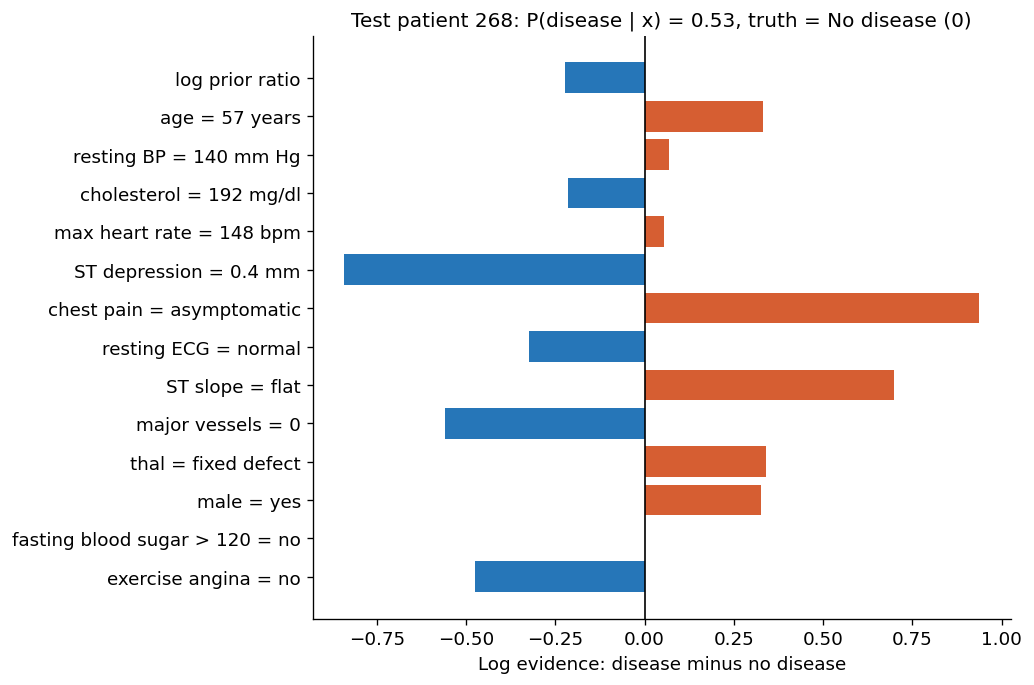

In [15]:
mixed_final = best_models['Mixed NB']  # Selected in Part 7: alpha = 20, fitted on the training rows.
p_disease = test_probabilities['Mixed NB'][:, 1]
row = test_idx[np.argmin(np.abs(p_disease - 0.5))]
x = X_mixed[row]

# One log-likelihood term per feature and class, shape (2 classes, number of features).
g = mixed_final.gaussian_
cont_terms = norm.logpdf(x[cols_cont], g.theta_, np.sqrt(g.var_))
cat_terms = np.column_stack([log_table[:, int(x[col])] for log_table, col
                             in zip(mixed_final.categorical_.feature_log_prob_, cols_cat)])
q = np.exp(mixed_final.binary_.feature_log_prob_)
bin_terms = np.where(x[cols_bin] == 1, np.log(q), np.log1p(-q))
log_ratio = np.hstack([cont_terms, cat_terms, bin_terms])
log_ratio = log_ratio[1] - log_ratio[0]
prior_ratio = mixed_final.log_prior_[1] - mixed_final.log_prior_[0]

# The bars must add up to the model's log posterior odds.
p_model = mixed_final.predict_proba(x[None])[0, 1]
assert np.isclose(prior_ratio + log_ratio.sum(), np.log(p_model / (1 - p_model)))

labels = ['log prior ratio'] + readable(heart.iloc[row])  # Same X_mixed column order as log_ratio.
values = np.r_[prior_ratio, log_ratio]

fig, ax = plt.subplots(figsize=(8.5, 5.6), layout='constrained')
ax.barh(labels[::-1], values[::-1], color=[COLORS[int(v > 0)] for v in values[::-1]])
ax.axvline(0, color='black', lw=1)
ax.set(xlabel='Log evidence: disease minus no disease',
       title=f'Test patient {row}: P(disease | x) = {p_model:.2f}, '
             f'truth = {CLASS_NAMES[y[row]]}')
plt.show()